In [4]:
import numpy as np
import fpw
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data_file = '../data/tydy.csv'
data = pd.read_csv(data_file, header=None).to_numpy()
times = data[:, 0]
flux = data[:, 1]
flux_err = data[:, 2]
print(times[-1]/86400)
print(np.std(flux))

plt.figure()
plt.errorbar(times, flux, yerr=flux_err, fmt='o')
plt.xlabel('Time')
plt.ylabel('Flux')
plt.title('Light Curve')
plt.show()

fgrid_file = '../data/fgrid.csv'
fgrid = pd.read_csv(fgrid_file, header=None).to_numpy().flatten()

fpw_pgram = fpw.run_fpw(times, flux, flux_err, fgrid, 20)

In [ ]:
#Make the FPW pgram into a dataframe and save it as a csv
fpw_df = pd.DataFrame(fpw_pgram)
fpw_df.to_csv('../data/CPU_periodogram.csv', index=False, header=False)

In [ ]:
print(fpw_pgram[0:10])

fgrid_file = '../data/fgrid.csv'
fgrid = pd.read_csv(fgrid_file, header=None).to_numpy().flatten()

cpu_pgram_file = '../data/CPU_periodogram.csv'
cpu_pgram = pd.read_csv(cpu_pgram_file, header=None).to_numpy().flatten()

# gpu_pgram_file = './data/GPU_periodogram.csv'
# gpu_pgram = pd.read_csv(gpu_pgram_file, header=None).to_numpy().flatten()

# residuals = gpu_pgram - cpu_pgram

plt.figure()
# plt.plot(fgrid, gpu_pgram, label='GPU', color='blue', alpha=0.5)
plt.plot(fgrid, cpu_pgram, label='CPU', color='red', alpha=0.5)
# plt.plot(fgrid, residuals, label='GPU - CPU', color='green', alpha=0.5)
plt.legend()
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.title('Frequency Power Spectrum')
plt.show()

# plt.figure()
# plt.hist(residuals, bins=100)
# plt.xlabel('Residuals')
# plt.ylabel('Count')
# plt.title('Residuals Histogram')
# plt.show()

#Print how many points are identical to their neighbor
identical_count = np.sum(np.diff(cpu_pgram) == 0)
identical_freqs = np.sum(np.diff(fgrid) == 0)
print(f'Number of identical consecutive values in FPW Random Periodogram: {identical_count}')
print(f'Number of identical consecutive frequencies in fgrid: {identical_freqs}')
print(f'Fraction of identical consecutive values in FPW Random Periodogram: {identical_count / len(cpu_pgram)}')

In [ ]:
random_lc_file = '../../build/last_source_lc.csv'
random_lc = pd.read_csv(random_lc_file, header=None).to_numpy()

plt.figure()
plt.errorbar(random_lc[:, 0], random_lc[:, 1], yerr=np.abs(random_lc[:, 2]), fmt='o')
plt.errorbar(random_lc[:, 0], random_lc[:, 3], yerr=np.abs(random_lc[:, 2]), fmt='o', alpha=0.5, color='orange')
plt.xlabel('Time')
plt.ylabel('Flux')
plt.title('Random Light Curve')
plt.ylim(-300, 300)
plt.show()

plt.figure()
plt.hist(random_lc[:, 1], bins=100, alpha=0.5, label='Original')
plt.hist(random_lc[:, 3], bins=100, alpha=0.5, label='Baseline Removed', color='orange')
plt.xlabel('Flux')
plt.ylabel('Count')
plt.title('Flux Histogram')
plt.legend()
plt.show()

mean_original = np.median(random_lc[:, 1])
mean_baseline_removed = np.median(random_lc[:, 3])
print(f'Mean of Original Flux: {mean_original}')
print(f'Mean of Baseline Removed Flux: {mean_baseline_removed}')

std_original = np.std(random_lc[:, 1])
std_baseline_removed = np.std(random_lc[:, 3])
print(f'Standard Deviation of Original Flux: {std_original}')
print(f'Standard Deviation of Baseline Removed Flux: {std_baseline_removed}')

In [ ]:
def freq_grid(t, fmin, fmax, oversample):
    """
    Generate a frequency grid based on input time values.

    Parameters:
    - t: List of time values.
    - fmin: Minimum frequency.
    - fmax: Maximum frequency (-1 to auto-adjust).
    - oversample: Oversampling factor.

    Returns:
    - List of frequency values.
    """

    trange = max(t) - min(t)

    sorted_t = sorted(t)
    diff_t = np.diff(sorted_t)  # Calculate differences between adjacent elements
    texp = min(diff_t)

    fres = 1.0 / (trange * oversample)
    if fmax == -1:
        fmax = 0.5 / texp  # Adjust fmax if set to -1
    if fmin == -1:
        fmin = fres  # Adjust fmin if set to -1

    fgrid = np.arange(fmin, fmax, fres).tolist()

    return fgrid

In [ ]:
fgrd = freq_grid(random_lc[:, 0], 1.0/(3.0*365), 1440/2.0, 3) # 3 year max period, 10 day min period
print(f'Generated frequency grid with {len(fgrd)} points from {fgrd[0]} to {fgrd[-1]}')

In [ ]:
random_pgram_file = '../../build/last_source_periodogram.csv'
random_pgram = pd.read_csv(random_pgram_file, header=None).to_numpy()

fgrid = random_pgram[:, 0]
power = random_pgram[:, 1]

#Run fpw on our random light curve
fpw_random_pgram = fpw.run_fpw(random_lc[:, 0], random_lc[:, 3], random_lc[:, 2], fgrid, 20)
fpw_10_bin = fpw.run_fpw(random_lc[:, 0], random_lc[:, 3], random_lc[:, 2], fgrid, 10)
fpw_5_bin = fpw.run_fpw(random_lc[:, 0], random_lc[:, 3], random_lc[:, 2], fgrid, 5)

In [ ]:
random_pgram_median = np.nanmedian(fpw_random_pgram)
random_pgram_mad = np.nanmedian(np.abs(fpw_random_pgram - random_pgram_median))

random_pgram_power = (fpw_random_pgram - random_pgram_median) / random_pgram_mad

plt.figure()
plt.plot(fgrid, power, label='Random Light Curve', color='purple', alpha=0.5)
plt.plot(fgrid, random_pgram_power, label='FPW Random Light Curve', color='orange', alpha=0.5)
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.title('Random Light Curve Frequency Power Spectrum')
plt.legend()
plt.show()

In [ ]:
fpw_random_pgram_clean = fpw_random_pgram[np.isfinite(fpw_random_pgram)]
fpw_10_bin_clean = fpw_10_bin[np.isfinite(fpw_10_bin)]
fpw_5_bin_clean = fpw_5_bin[np.isfinite(fpw_5_bin)]
plt.figure()
plt.hist(fpw_random_pgram_clean, bins=100, alpha=0.5, label='20 bins', color='orange')
plt.hist(fpw_10_bin_clean, bins=100, alpha=0.5, label='10 Bins', color='green')
plt.hist(fpw_5_bin_clean, bins=100, alpha=0.5, label='5 Bins', color='blue')
plt.legend()
plt.xlabel('Power')
plt.ylabel('Count')
plt.title('FPW Periodogram Histogram, arbitrary source')
plt.xlim(15, 100)
plt.show()

mad = np.median(np.abs(fpw_random_pgram_clean - np.median(fpw_random_pgram_clean)))

k = np.mean(fpw_random_pgram_clean)
med_comp = k * (1 - 2/(9 * k))**3

std = np.std(fpw_random_pgram_clean)
mad_comp = 1.483 * std

med_20 = np.median(fpw_random_pgram_clean)
med_10 = np.median(fpw_10_bin_clean)
med_5 = np.median(fpw_5_bin_clean)
print(f"median of 20 bins: {med_20}")
print(f"median of 10 bins: {med_10}")
print(f"median of 5 bins: {med_5}")

mean_20 = np.mean(fpw_random_pgram_clean)
mean_10 = np.mean(fpw_10_bin_clean)
mean_5 = np.mean(fpw_5_bin_clean)
print(f"mean of 20 bins: {mean_20}")
print(f"mean of 10 bins: {mean_10}")
print(f"mean of 5 bins: {mean_5}")

def derived_median(mean):
    return mean * (1 - 2/(9 * mean))**3

derived_median_20 = derived_median(mean_20)
derived_median_10 = derived_median(mean_10)
derived_median_5 = derived_median(mean_5)
print(f"derived median of 20 bins: {derived_median_20}")
print(f"derived median of 10 bins: {derived_median_10}")
print(f"derived median of 5 bins: {derived_median_5}")

min_20 = np.min(fpw_random_pgram_clean)
min_10 = np.min(fpw_10_bin_clean)
min_5 = np.min(fpw_5_bin_clean)
print(f"min of 20 bins: {min_20}")
print(f"min of 10 bins: {min_10}")
print(f"min of 5 bins: {min_5}")

In [ ]:
#Try fitting a skew normal distribution to the power spectrum
from scipy.stats import skewnorm
# from scipy.stats import gamma
from scipy.optimize import curve_fit

#Get the histogram of the power spectrum
hist, bin_edges = np.histogram(fpw_random_pgram_clean, bins=100, density=True)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

#Normalize the histogram
hist_sum = np.sum(hist)
hist /= hist_sum

print(f"Sum of histogram: {hist_sum}")

max_bin = bin_centers[np.argmax(hist)]

plt.figure()
plt.plot(bin_centers, hist, 'o', label='Data', color='purple')
#Plot a skew normal distribution
x = np.linspace(0, np.max(bin_centers), 1000)
skew_norm = 3.75 * skewnorm.pdf(x, a=3, loc=max_bin - 15, scale=36)
plt.plot(x, skew_norm, label='Skew Normal Distribution (shape=3)', color='orange')
plt.title('Power Spectrum Histogram with Skew Normal Fit')
plt.xlabel('Power')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

In [ ]:
weighted_lc_mean = np.average(random_lc[:, 3], weights=1/random_lc[:, 2]**2)
weighted_lc_std = np.sqrt(1/np.sum(1/random_lc[:, 2]**2))
weighted_raw_mean = np.average(random_lc[:, 1], weights=1/random_lc[:, 2]**2)

print(f'Weighted Mean of Baseline Removed Flux: {weighted_lc_mean}')
print(f'Weighted Std of Baseline Removed Flux: {weighted_lc_std}')
# print(f'Weighted Mean of Raw Flux: {weighted_raw_mean}')

plt.hist(random_lc[:, 2][np.isfinite(random_lc[:, 2])], bins=100)

In [ ]:
#Count the nan values in the fpw random pgram
nan_count = np.sum(np.isnan(fpw_random_pgram))
print(f'Number of NaN values in FPW Random Periodogram: {nan_count}')

#Find the indices of the NaN values in the fpw random pgram
nan_indices = np.where(np.isnan(fpw_random_pgram))[0]
print(f'Indices of NaN values in FPW Random Periodogram: {nan_indices}')

nan_median = np.nanmedian(fpw_random_pgram)
print(f'Median of FPW Random Periodogram (excluding NaNs): {nan_median}')
nan_mad = np.nanmedian(np.abs(fpw_random_pgram - nan_median))
print(f'Median Absolute Deviation of FPW Random Periodogram (excluding NaNs): {nan_mad}')

#Count how many values are identical to a value next to it
identical_count = np.sum(np.diff(power) == 0)
print(f'Number of identical consecutive values in FPW Random Periodogram: {identical_count}')

In [ ]:
#Subtract the two periodograms and plot the histogram of the residuals
residuals = random_pgram_power - power
plt.figure()
plt.hist(residuals, bins=100, alpha=0.5, color='green')
plt.xlabel('Residuals')
plt.ylabel('Count')
plt.title('Residuals Histogram of Random Light Curve')
plt.show()

In [ ]:
#Load in the peaks
peaks_file = '../../build/last_source_peaks.csv'
peaks = pd.read_csv(peaks_file, header=None).to_numpy()

indices = peaks[:, 0]
vals = peaks[:, 1]

max_index = np.argmax(power)
max_value = np.max(power)

print(f'Maximum value in power spectrum: {max_index} with value {max_value}')
print(f'Top peak index from GPU: {indices[0]} with value {vals[0]}')

In [ ]:
random_lc_file = '../../build/last_source_lc.csv'
random_lc = pd.read_csv(random_lc_file, header=None).to_numpy()

times = random_lc[:, 0]
flux = random_lc[:, 1]
flux_err = random_lc[:, 2]
valid = np.isfinite(flux) & np.isfinite(flux_err)
times = times[valid]
flux = flux[valid]
flux_err = flux_err[valid]


plt.figure()
plt.errorbar(times, flux, flux_err, fmt='o')

In [ ]:
# def remove_deep_drilling(bjd):
#     dt = 40.0  # seconds
#     bjd_new = []
#     for ud in np.unique(np.floor(bjd)):
#         bjd_day = bjd[(bjd > ud) & (bjd < ud + 1.0)]
#         Nz = len(bjd_day)

#         deep_counter = 0
#         # If more than 10 exposures in a night, check time sampling
#         if Nz > 10:
#             tsec = bjd_day * 86400
#             zdiff = ((tsec[1:] - tsec[:-1]) < dt)

#             # Handle some edge cases
#             if zdiff[0] == True:
#                 zdiff = np.insert(zdiff,0,True)
#             else:
#                 zdiff = np.insert(zdiff,0,False)
#             for j in range(len(zdiff)):
#                 if j == 0:
#                     continue
#                 if zdiff[j] == True:
#                     zdiff[j-1] = True

#             # Only keep exposures with sampling > dt       
#             bjd_new.append(bjd_day[~zdiff].copy(deep=True))
#         else:
#             bjd_new.append(bjd_day)
#     bjd = np.concatenate(bjd_new)
#     bjd = np.sort(bjd)
#     return bjd

def count_deep_drilling(bjd):
    dt = 5 * 60.0  # seconds
    deep_drilling_counts = 0
    for i in range(1, len(bjd)):
        if (bjd[i] - bjd[i-1]) * 86400 < dt:
            deep_drilling_counts += 1
    return deep_drilling_counts


In [ ]:
#Check the hdf5 file
file = '/data/zvar/matchfiles/0567/data_0567_01_1_zg.h5'
import h5py
with h5py.File(file, 'r') as f:
    times = np.array(f['data']['exposures']['bjd'])

times -= np.min(times)
times = np.sort(times)
ones = np.ones_like(times)
plt.plot(times, ones, 'o', alpha=0.1)

counts = count_deep_drilling(times)
print(counts)

bjd_diffs = np.diff(times * 86400)
sorted_diffs = np.sort(bjd_diffs)
print(sorted_diffs[0:20])

44103
44103
Number of NaN values in Flux MAD: 4313
Number of NaN values in Periodogram Median (20 bins): 4281
Number of NaN values in Periodogram MAD (20 bins): 4281
Number of 0 values in Flux MAD: 0
Number of 0 values in Periodogram Median (20 bins): 0
Number of 0 values in Periodogram MAD (20 bins): 0
39789


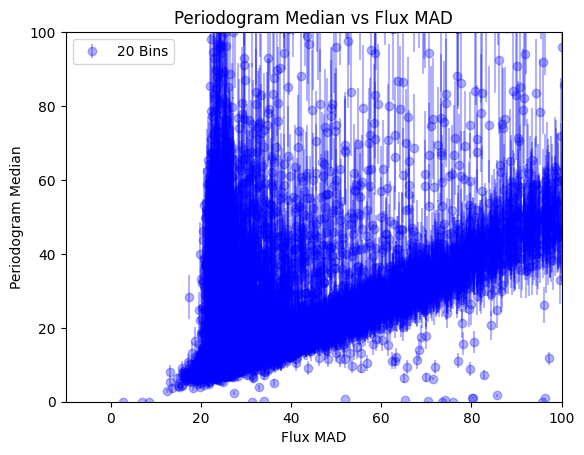

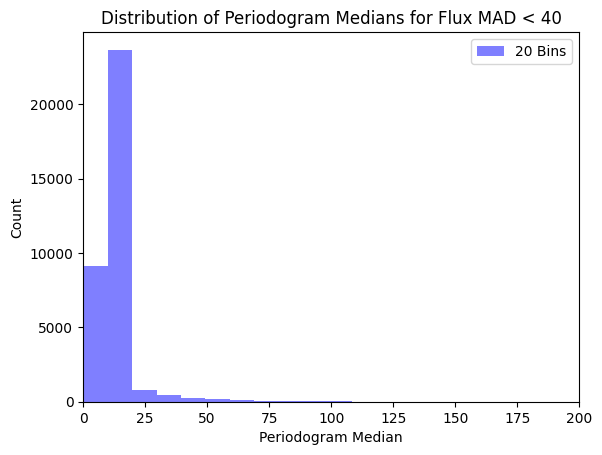

In [5]:
#Load flux statistics
flux_stats_file = '../../build/flux_statistics.csv'
flux_stats = pd.read_csv(flux_stats_file).to_numpy()

flux_idx = flux_stats[:, 0]
flux_median = flux_stats[:, 1]
flux_mad = flux_stats[:, 2]
flux_amp = flux_stats[:, 3]

#Load periodogram statistics
periodogram_stats_file_20 = '../../build/periodogram_statistics_bin_0.csv'
periodogram_stats_file_10 = '../../build/periodogram_statistics_bin_1.csv'
periodogram_stats_file_5 = '../../build/periodogram_statistics_bin_2.csv'
periodogram_stats_20 = pd.read_csv(periodogram_stats_file_20).to_numpy()
periodogram_stats_10 = pd.read_csv(periodogram_stats_file_10).to_numpy()
periodogram_stats_5 = pd.read_csv(periodogram_stats_file_5).to_numpy()

periodogram_idx_20 = periodogram_stats_20[:, 0]
periodogram_median_20 = periodogram_stats_20[:, 1]
periodogram_mad_20 = periodogram_stats_20[:, 2]

periodogram_idx_10 = periodogram_stats_10[:, 0]
periodogram_median_10 = periodogram_stats_10[:, 1]
periodogram_mad_10 = periodogram_stats_10[:, 2]

periodogram_idx_5 = periodogram_stats_5[:, 0]
periodogram_median_5 = periodogram_stats_5[:, 1]
periodogram_mad_5 = periodogram_stats_5[:, 2]

print(len(flux_mad))
print(len(periodogram_median_20))

#Count how many nans are in each array
nan_flux_mad = np.sum(np.isnan(flux_mad))
nan_periodogram_median_20 = np.sum(np.isnan(periodogram_median_20))
nan_periodogram_mad_20 = np.sum(np.isnan(periodogram_mad_20))
print(f'Number of NaN values in Flux MAD: {nan_flux_mad}')
print(f'Number of NaN values in Periodogram Median (20 bins): {nan_periodogram_median_20}')
print(f'Number of NaN values in Periodogram MAD (20 bins): {nan_periodogram_mad_20}')

#Count 0s in the arrays
zero_flux_mad = np.sum(flux_mad == 0)
zero_periodogram_median_20 = np.sum(periodogram_median_20 == 0)
zero_periodogram_mad_20 = np.sum(periodogram_mad_20 == 0)
print(f'Number of 0 values in Flux MAD: {zero_flux_mad}')
print(f'Number of 0 values in Periodogram Median (20 bins): {zero_periodogram_median_20}')
print(f'Number of 0 values in Periodogram MAD (20 bins): {zero_periodogram_mad_20}')

#Clean out the values where either the flux mad is zero or the periodogram median is zero
# valid_20 = np.isfinite(flux_mad) & np.isfinite(periodogram_median_20) & (flux_mad != 0) & (periodogram_median_20 > 20)
valid_20 = np.isfinite(flux_mad) & np.isfinite(periodogram_median_20) & (flux_mad != 0)
flux_mad_20 = flux_mad[valid_20]
flux_amp_20 = flux_amp[valid_20]
periodogram_median_20 = periodogram_median_20[valid_20]
periodogram_mad_20 = periodogram_mad_20[valid_20]

print(len(periodogram_median_20))

#Outlier rejection
valid = np.abs(periodogram_median_20) < 1000
flux_mad_20 = flux_mad_20[valid]
flux_amp_20 = flux_amp_20[valid]
periodogram_median_20 = periodogram_median_20[valid]
periodogram_mad_20 = periodogram_mad_20[valid]

dist_data = np.where((flux_mad_20 < 40))[0]
dist_medians = periodogram_median_20[dist_data]

x_range = np.linspace(0, 1500, 1000)
plt.figure()
plt.errorbar(flux_mad_20, periodogram_median_20, yerr=periodogram_mad_20, fmt='o', alpha=0.3, label='20 Bins', color='blue')
# plt.errorbar(fit_domain, fit_range, yerr=fit_error, fmt='o', alpha=0.5, label='20 Bins', color='blue', zorder=10)
# plt.plot(flux_mad, periodogram_median_10, 'o', alpha=0.5, label='10 Bins', color='orange')
# plt.plot(flux_mad, periodogram_median_5, 'o', alpha=0.5, label='5 Bins', color='green')
plt.xlim(-10, 100)
plt.ylim(0, 100)
# plt.ylim(0, 1000)
# plt.xscale('log')
# plt.yscale('log')
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('Periodogram Median vs Flux MAD')
plt.legend()
plt.show()

plt.figure()
plt.hist(dist_medians, bins=100, alpha=0.5, label='20 Bins', color='blue')
plt.title('Distribution of Periodogram Medians for Flux MAD < 40')
plt.xlabel('Periodogram Median')
plt.ylabel('Count')
plt.legend()
plt.xlim(0, 200)
plt.show()

In [6]:
#Cut to the regime where flux_mad is not a good enough estimator
mask = flux_mad_20 < 40
flux_amp_20_low_mad = flux_amp_20[mask]
flux_mad_20_low_mad = flux_mad_20[mask]
periodogram_median_20_low_mad = periodogram_median_20[mask]
periodogram_mad_20_low_mad = periodogram_mad_20[mask]

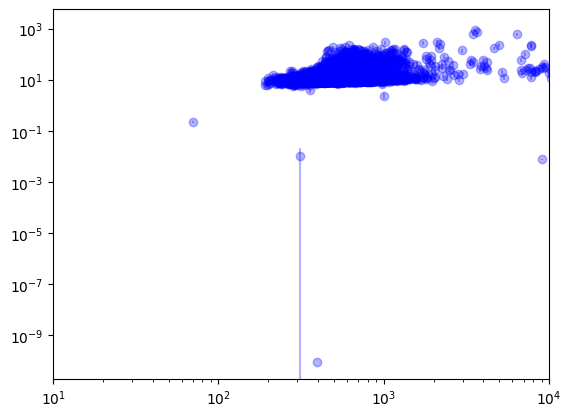

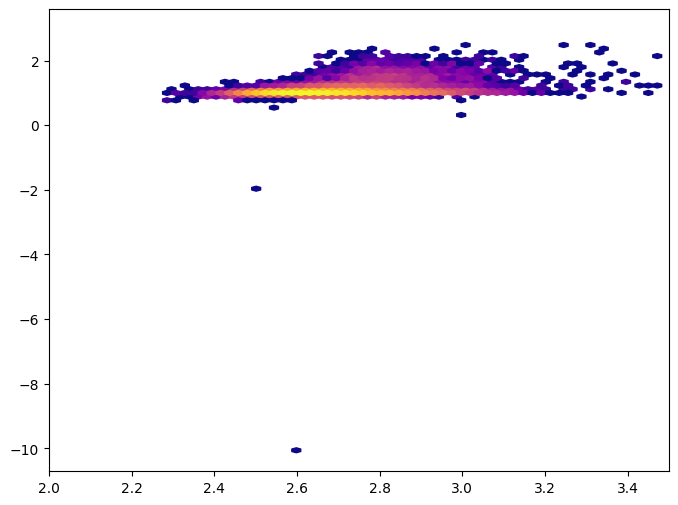

In [7]:
plt.figure()
plt.errorbar(flux_amp_20_low_mad, periodogram_median_20_low_mad, yerr=periodogram_mad_20_low_mad, fmt='o', alpha=0.3, label='20 Bins', color='blue')
plt.xscale('log')
plt.yscale('log')
plt.xlim(10, 1e4)
# plt.ylim(0, 100)
plt.show()

valid = np.logical_and(flux_amp_20_low_mad > 10, flux_amp_20_low_mad < 1e4)
plt.figure(figsize=(8, 6))
plt.hexbin(np.log10(flux_amp_20_low_mad[valid]), np.log10(periodogram_median_20_low_mad[valid]), gridsize=100, cmap='plasma', bins='log')
plt.xlim(2, 3.5)
plt.show()

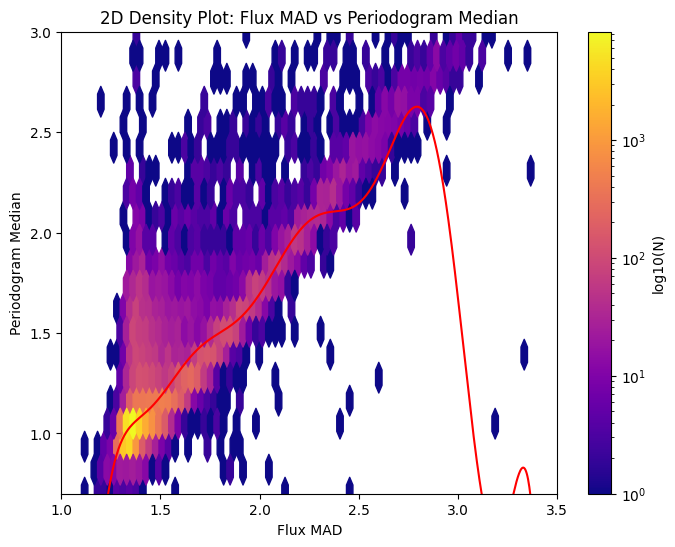

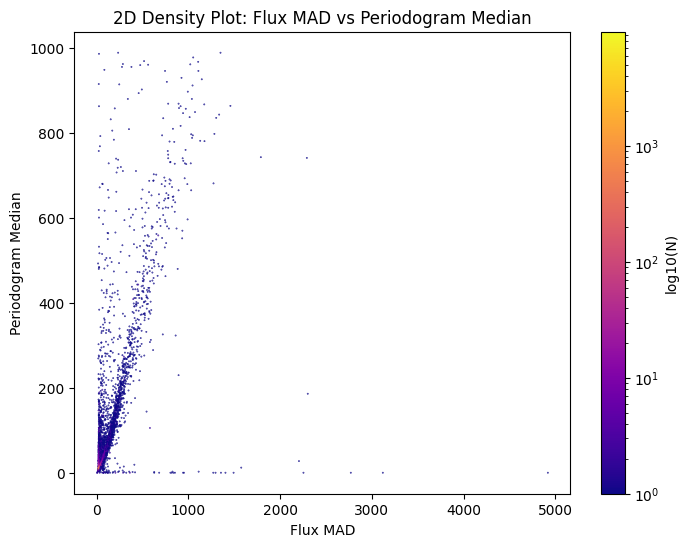

In [9]:
#Fit a polynomial
coeffs = np.polyfit(np.log10(flux_mad_20), np.log10(periodogram_median_20), 13)
poly = np.poly1d(coeffs)

x_range = np.linspace(np.min(np.log10(flux_mad_20)), np.max(np.log10(flux_mad_20)), 1000)
y_range = poly(x_range)
plt.figure(figsize=(8, 6))
plt.hexbin(np.log10(flux_mad_20), np.log10(periodogram_median_20), gridsize=100, cmap='plasma', bins='log')
plt.plot(x_range, y_range, color='red')
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('2D Density Plot: Flux MAD vs Periodogram Median')
plt.colorbar(label='log10(N)')
# plt.xlim(-10, 400)
# plt.ylim(-10, 400)
plt.xlim(1, 3.5)
plt.ylim(0.7, 3)
plt.show()

plt.figure(figsize=(8, 6))
plt.hexbin(flux_mad_20, periodogram_median_20, gridsize=1000, cmap='plasma', bins='log')
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('2D Density Plot: Flux MAD vs Periodogram Median')
plt.colorbar(label='log10(N)')
# plt.xlim(0, 100)
# plt.ylim(0, 50)
plt.show()

39789


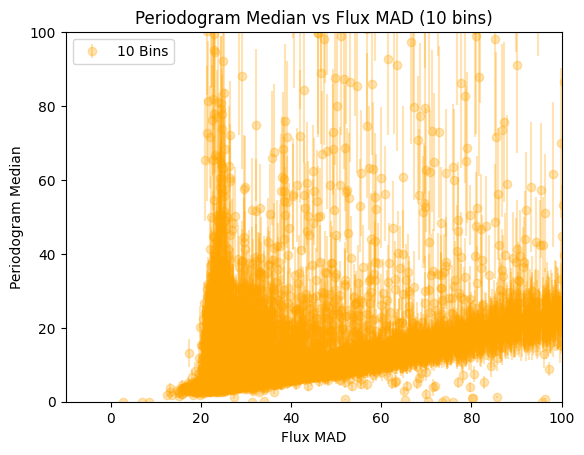

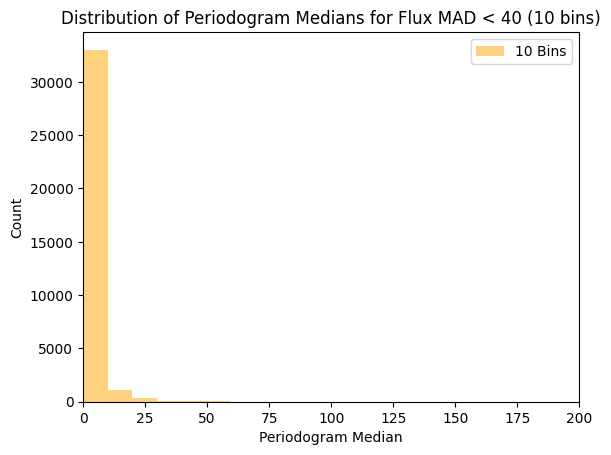

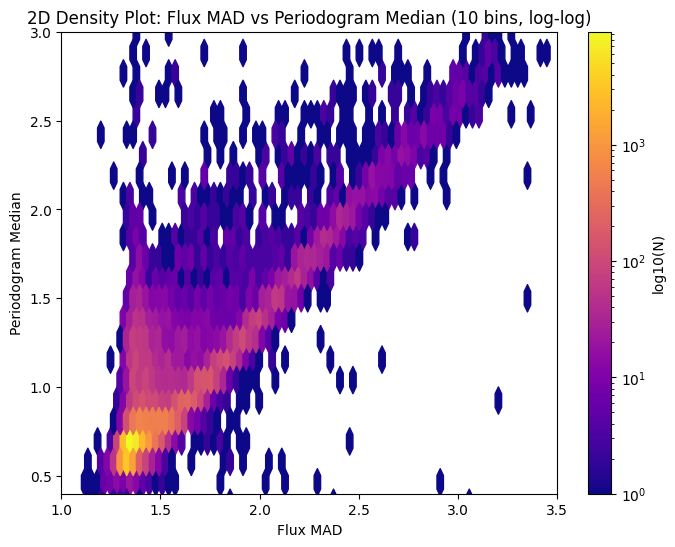

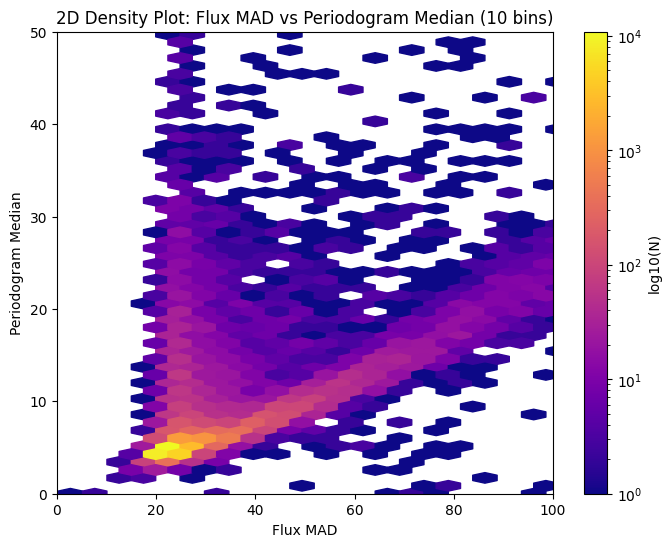

In [10]:
# Clean out the values where either the flux mad is zero or the periodogram median is zero
valid_10 = np.isfinite(flux_mad) & np.isfinite(periodogram_median_10) & (flux_mad != 0)
flux_mad_10 = flux_mad[valid_10]
flux_amp_10 = flux_amp[valid_10]
periodogram_median_10 = periodogram_median_10[valid_10]
periodogram_mad_10 = periodogram_mad_10[valid_10]

print(len(periodogram_median_10))

# Outlier rejection
valid = np.abs(periodogram_median_10) < 1000
flux_mad_10 = flux_mad_10[valid]
flux_amp_10 = flux_amp_10[valid]
periodogram_median_10 = periodogram_median_10[valid]
periodogram_mad_10 = periodogram_mad_10[valid]

dist_data = np.where((flux_mad_10 < 40))[0]
dist_medians = periodogram_median_10[dist_data]

x_range = np.linspace(0, 1500, 1000)
plt.figure()
plt.errorbar(flux_mad_10, periodogram_median_10, yerr=periodogram_mad_10, fmt='o', alpha=0.3, label='10 Bins', color='orange')
plt.xlim(-10, 100)
plt.ylim(0, 100)
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('Periodogram Median vs Flux MAD (10 bins)')
plt.legend()
plt.show()

plt.figure()
plt.hist(dist_medians, bins=100, alpha=0.5, label='10 Bins', color='orange')
plt.title('Distribution of Periodogram Medians for Flux MAD < 40 (10 bins)')
plt.xlabel('Periodogram Median')
plt.ylabel('Count')
plt.legend()
plt.xlim(0, 200)
plt.show()

plt.figure(figsize=(8, 6))
plt.hexbin(np.log10(flux_mad_10), np.log10(periodogram_median_10), gridsize=100, cmap='plasma', bins='log')
# plt.plot(x_range, y_range, color='red')  # Only include if you have y_range for 10 bins
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('2D Density Plot: Flux MAD vs Periodogram Median (10 bins, log-log)')
plt.colorbar(label='log10(N)')
plt.xlim(1, 3.5)
plt.ylim(0.4, 3)
plt.show()

plt.figure(figsize=(8, 6))
plt.hexbin(flux_mad_10, periodogram_median_10, gridsize=1000, cmap='plasma', bins='log')
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('2D Density Plot: Flux MAD vs Periodogram Median (10 bins)')
plt.colorbar(label='log10(N)')
plt.xlim(0, 100)
plt.ylim(0, 50)
plt.show()

39789


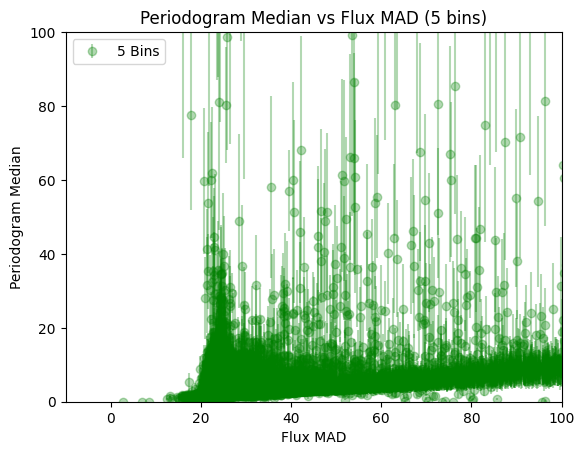

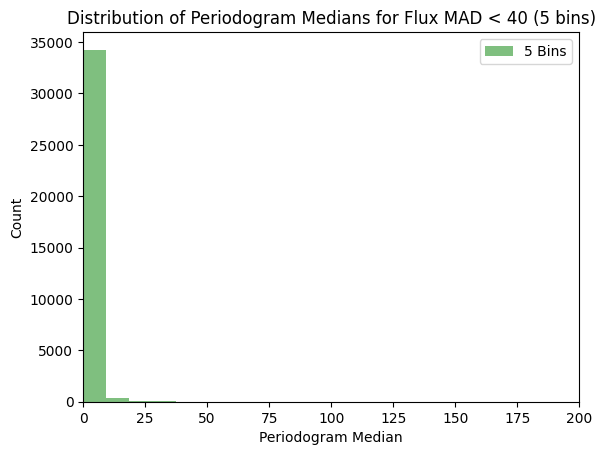

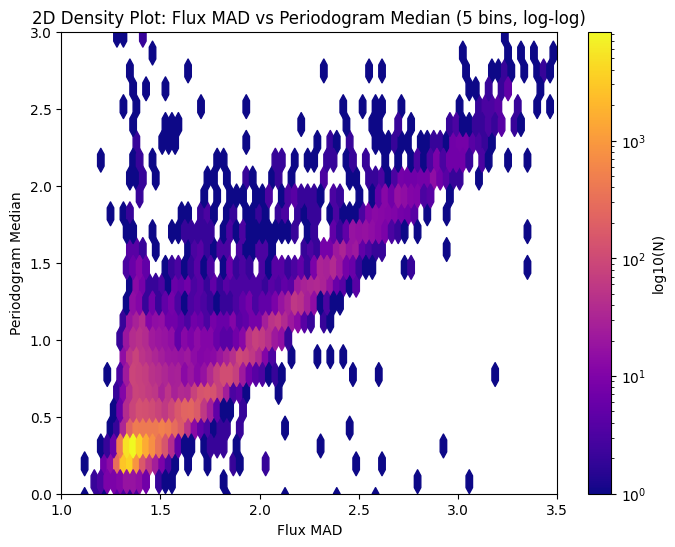

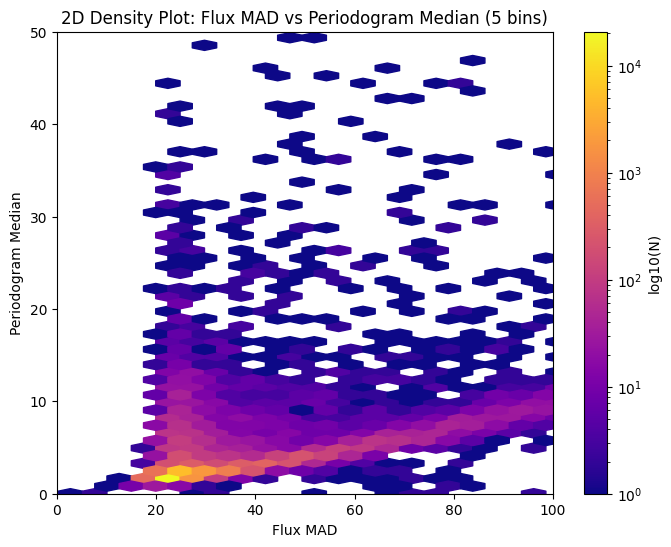

In [11]:
# Clean out the values where either the flux mad is zero or the periodogram median is zero
valid_5 = np.isfinite(flux_mad) & np.isfinite(periodogram_median_5) & (flux_mad != 0)
flux_mad_5 = flux_mad[valid_5]
flux_amp_5 = flux_amp[valid_5]
periodogram_median_5 = periodogram_median_5[valid_5]
periodogram_mad_5 = periodogram_mad_5[valid_5]

print(len(periodogram_median_5))

# Outlier rejection
valid = np.abs(periodogram_median_5) < 1000
flux_mad_5 = flux_mad_5[valid]
flux_amp_5 = flux_amp_5[valid]
periodogram_median_5 = periodogram_median_5[valid]
periodogram_mad_5 = periodogram_mad_5[valid]

dist_data = np.where((flux_mad_5 < 40))[0]
dist_medians = periodogram_median_5[dist_data]

x_range = np.linspace(0, 1500, 1000)
plt.figure()
plt.errorbar(flux_mad_5, periodogram_median_5, yerr=periodogram_mad_5, fmt='o', alpha=0.3, label='5 Bins', color='green')
plt.xlim(-10, 100)
plt.ylim(0, 100)
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('Periodogram Median vs Flux MAD (5 bins)')
plt.legend()
plt.show()

plt.figure()
plt.hist(dist_medians, bins=100, alpha=0.5, label='5 Bins', color='green')
plt.title('Distribution of Periodogram Medians for Flux MAD < 40 (5 bins)')
plt.xlabel('Periodogram Median')
plt.ylabel('Count')
plt.legend()
plt.xlim(0, 200)
plt.show()

plt.figure(figsize=(8, 6))
plt.hexbin(np.log10(flux_mad_5), np.log10(periodogram_median_5), gridsize=100, cmap='plasma', bins='log')
# plt.plot(x_range, y_range, color='red')  # Only include if you have y_range for 5 bins
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('2D Density Plot: Flux MAD vs Periodogram Median (5 bins, log-log)')
plt.colorbar(label='log10(N)')
plt.xlim(1, 3.5)
plt.ylim(0, 3)
plt.show()

plt.figure(figsize=(8, 6))
plt.hexbin(flux_mad_5, periodogram_median_5, gridsize=1000, cmap='plasma', bins='log')
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('2D Density Plot: Flux MAD vs Periodogram Median (5 bins)')
plt.colorbar(label='log10(N)')
plt.xlim(0, 100)
plt.ylim(0, 50)
plt.show()

In [3]:
#Load the object csv
data = pd.read_csv('../../build/object_474_chunk_0.csv')
flux = data['FluxNoBaseline'].to_numpy()
print(np.median(flux))

def mad(data):
    return np.median(np.abs(data - np.median(data)))

print(mad(flux))

1.92706
32.60876


In [ ]:
# Clean out the values where either the flux MAD is zero or the periodogram median is zero
valid_10 = np.isfinite(flux_mad) & np.isfinite(periodogram_median_10) & (flux_mad != 0) & (periodogram_median_10 > 10)
flux_mad_10 = flux_mad[valid_10]
periodogram_median_10 = periodogram_median_10[valid_10]
periodogram_mad_10 = periodogram_mad_10[valid_10]

# Outlier rejection
valid = np.abs(periodogram_median_10) < 1000
flux_mad_10 = flux_mad_10[valid]
periodogram_median_10 = periodogram_median_10[valid]
periodogram_mad_10 = periodogram_mad_10[valid]

fit_limit = np.where((flux_mad_10 > 60))[0]
fit_domain = flux_mad_10[fit_limit]
fit_range = periodogram_median_10[fit_limit]
fit_error = periodogram_mad_10[fit_limit]

# Fit with curve fit
popt, pcov = curve_fit(line, fit_domain, fit_range, sigma=fit_error, p0=[1, 1])
a_fit, b_fit = popt
print(f'Fitted line: y = {a_fit:.2f} * x + {b_fit:.2f}')

dist_data = np.where((flux_mad_10 < 60))[0]
dist_medians = periodogram_median_10[dist_data]

plt.figure()
plt.errorbar(flux_mad_10, periodogram_median_10, yerr=periodogram_mad_10, fmt='o', alpha=0.5, label='10 Bins', color='orange')
plt.plot(fit_domain, line(fit_domain, *popt), label='Fitted Line', color='red', zorder=20)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel('Flux MAD')
plt.ylabel('Periodogram Median')
plt.title('Flux vs Periodogram Median (10 Bins)')
plt.legend()
plt.show()

plt.figure()
plt.hist(dist_medians, bins=100, alpha=0.5, label='10 Bins', color='orange')
plt.xlim(0, 100)
plt.show()